# Environment and Data: InvertedPendulum
**Environment:** `InvertedPendulum-v5` (Gymnasium, MuJoCo)
**Datasets:** `mujoco/invertedpendulum/medium-v0`, `mujoco/invertedpendulum/expert-v0` (Minari)
**Goal of this notebook:** describe the environment, show how a random agent behaves, and look at what is stored in the offline datasets that AWAC learns from.

### Install required libraries:

In [1]:
# minari[hf,hdf5]   - Minari datasets: "hf" downloads them from Hugging Face, "hdf5" reads the files
# gymnasium[mujoco] - the InvertedPendulum environment and the MuJoCo physics simulator
# imageio           - saves the rendered frames as a GIF for the slides
%pip install -q --disable-pip-version-check "minari[hf,hdf5]" "gymnasium[mujoco]" matplotlib imageio pandas

Note: you may need to restart the kernel to use updated packages.


### Imports and output folder:

In [2]:
import os
import warnings

import gymnasium as gym
import imageio
import matplotlib.pyplot as plt
import minari
import numpy as np
import pandas as pd
from huggingface_hub.utils import logging as hf_logging
from IPython.display import Image, display

# Hide two harmless messages so that the outputs stay readable:
# Minari's "dataset already downloaded" warning and Hugging Face's "no HF_TOKEN" notice
warnings.filterwarnings("ignore", message="Skipping Download")
hf_logging.set_verbosity_error()

# Folder for figures and the GIF used in the slides / video
os.makedirs("figures", exist_ok=True)

# Fixed random seed, so every run of the notebook gives the same numbers
SEED = 0

## 1. The environment

InvertedPendulum is the classic CartPole task inside the MuJoCo physics simulator: a cart moves along a rail
and a pole is attached to it by a hinge. The agent pushes the cart left and right so that the pole does not fall.

| | |
|---|---|
| **State** | 4 continuous numbers: cart position, pole angle (rad), cart velocity, pole angular velocity |
| **Action** | 1 continuous number in $[-3, 3]$: the force applied to the cart |
| **Reward** | $+1$ for every step the pole stays upright, $0$ on the step where it falls |
| **Start state** | all 4 values are close to 0, with uniform noise in $[-0.01, 0.01]$ |
| **Terminal state** | the pole angle leaves $[-0.2, 0.2]$ rad (about 11.5°), or the state becomes non-finite |
| **Truncation** | the episode is cut after 1000 steps, so the maximum return is 1000 |

Both the state space and the action space are **continuous**. This is why the environment fits AWAC:
the actor of AWAC outputs a continuous action (a Gaussian policy), so it cannot be used on discrete tasks
such as the original CartPole.

In [3]:
# Create the environment; "rgb_array" lets env.render() return a picture of the current frame
env = gym.make("InvertedPendulum-v5", render_mode="rgb_array")

# Box(-inf, inf, (4,)) = 4 unbounded real numbers; Box(-3, 3, (1,)) = 1 real number between -3 and 3
print("Observation space:", env.observation_space)
print("Action space:     ", env.action_space)
print("Max episode steps:", env.spec.max_episode_steps)

# reset() starts a new episode and returns the first state (all values close to 0 = pole upright)
obs, _ = env.reset(seed=SEED)
print("Initial observation [cart pos, pole angle, cart vel, pole ang. vel]:", np.round(obs, 4))

Observation space: Box(-inf, inf, (4,), float64)
Action space:      Box(-3.0, 3.0, (1,), float32)
Max episode steps: 1000
Initial observation [cart pos, pole angle, cart vel, pole ang. vel]: [ 0.0027 -0.0046 -0.0092 -0.0097]


## 2. A random agent

Before training anything, we check how a policy that picks random actions from $[-3, 3]$ behaves.
This is the lower bound that any learned agent must beat.

In [4]:
def run_random_episodes(env, n_episodes, seed):
    # Run a uniformly random policy and collect return, length, ending type and actions of each episode
    env.action_space.seed(seed)  # makes action_space.sample() reproducible
    returns, lengths, terminated_flags, actions = [], [], [], []
    for i in range(n_episodes):
        env.reset(seed=seed + i)  # a different but reproducible start state for each episode
        done, ep_return, ep_len = False, 0.0, 0
        while not done:
            action = env.action_space.sample()  # random force in [-3, 3]
            _, reward, terminated, truncated, _ = env.step(action)
            ep_return += reward
            ep_len += 1
            actions.append(action[0])
            # terminated = the pole fell (terminal state), truncated = the 1000-step limit was reached
            done = terminated or truncated
        returns.append(ep_return)
        lengths.append(ep_len)
        terminated_flags.append(terminated)
    return np.array(returns), np.array(lengths), np.array(terminated_flags), np.array(actions)


random_returns, random_lengths, random_terminated, random_actions = run_random_episodes(env, n_episodes=100, seed=SEED)
print("Random policy over 100 episodes:")
print(f"  mean return = {random_returns.mean():.2f} ± {random_returns.std():.2f}")
print(f"  mean length = {random_lengths.mean():.2f} steps (min {random_lengths.min()}, max {random_lengths.max()})")

Random policy over 100 episodes:
  mean return = 5.23 ± 3.68
  mean length = 6.23 steps (min 3, max 23)


### What the fall looks like

We record one random episode, save it as a GIF for the video, and plot the pole angle step by step
together with the termination threshold of $\pm 0.2$ rad.

The pole fell after 5 steps, final angle = 0.329 rad


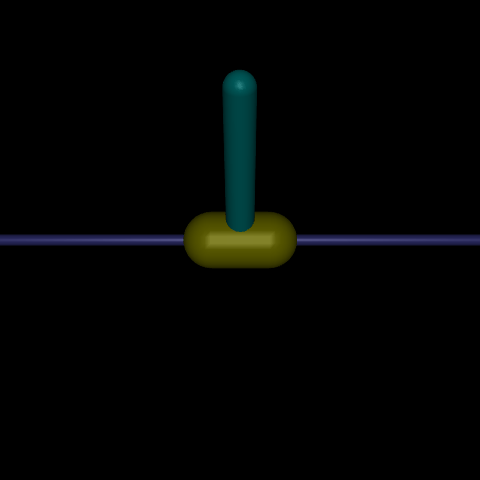

In [5]:
# Play one random episode and keep a picture and the pole angle (obs[1]) of every step
env.action_space.seed(SEED)
obs, _ = env.reset(seed=SEED)
frames, angles, actions = [env.render()], [obs[1]], []
done = False
while not done:
    action = env.action_space.sample()
    obs, reward, terminated, truncated, _ = env.step(action)
    frames.append(env.render())
    angles.append(obs[1])
    actions.append(action[0])
    done = terminated or truncated

print(f"The pole fell after {len(actions)} steps, final angle = {angles[-1]:.3f} rad")

# Slow GIF (about 3 frames per second, duration is in ms per frame) so the fall is visible on the slides
imageio.mimsave("figures/random_agent.gif", frames, duration=300, loop=0)
display(Image(filename="figures/random_agent.gif"))

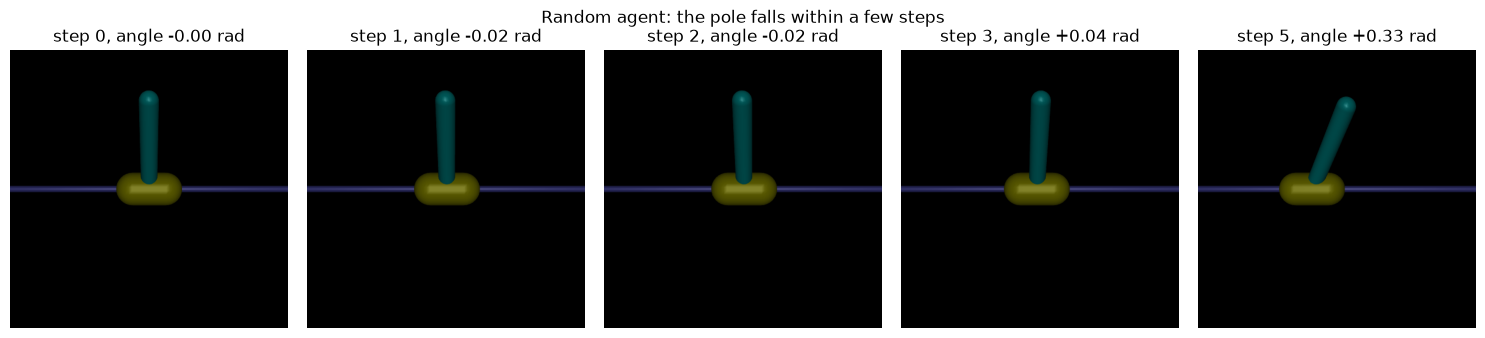

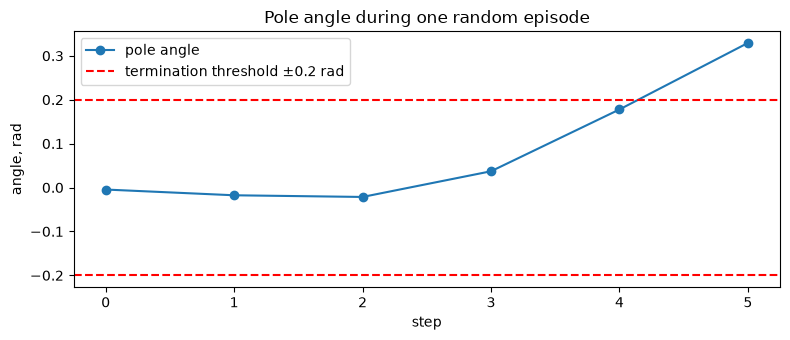

In [6]:
# Frame strip: 5 evenly spaced frames from the start of the episode to the moment of the fall
idx = np.linspace(0, len(frames) - 1, 5).astype(int)
fig, axes = plt.subplots(1, len(idx), figsize=(15, 3.4))
for ax, i in zip(axes, idx):
    ax.imshow(frames[i])
    ax.set_title(f"step {i}, angle {angles[i]:+.2f} rad")
    ax.axis("off")
plt.suptitle("Random agent: the pole falls within a few steps")
plt.tight_layout()
plt.savefig("figures/random_agent_frames.png", dpi=120, bbox_inches="tight")
plt.show()

# Pole angle over time: the episode ends as soon as the line crosses a red threshold
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(angles, marker="o", label="pole angle")
ax.axhline(0.2, color="red", linestyle="--", label="termination threshold ±0.2 rad")
ax.axhline(-0.2, color="red", linestyle="--")
ax.set_xlabel("step")
ax.set_ylabel("angle, rad")
ax.set_title("Pole angle during one random episode")
ax.legend()
plt.tight_layout()
plt.savefig("figures/random_agent_angle.png", dpi=120, bbox_inches="tight")
plt.show()

## 3. The offline datasets

AWAC first learns from a fixed dataset of transitions $(s, a, r, s')$ recorded by another agent.
We use two datasets from Minari for the same environment:

* **medium-v0**: recorded by a weak agent; this is the dataset AWAC is trained on;
* **expert-v0**: recorded by a strong agent; used only as a reference for comparison.

In [7]:
DATASETS = {
    "medium": "mujoco/invertedpendulum/medium-v0",
    "expert": "mujoco/invertedpendulum/expert-v0",
}

datasets = {}
for name, dataset_id in DATASETS.items():
    # Downloads the dataset to ~/.minari/datasets (skipped if it is already there) and opens it
    minari.download_dataset(dataset_id)
    datasets[name] = minari.load_dataset(dataset_id)
    ds = datasets[name]
    print(f"{dataset_id}: {ds.total_episodes} episodes, {ds.total_steps} steps, env = {ds.spec.env_spec.id}")

mujoco/invertedpendulum/medium-v0: 1040 episodes, 99075 steps, env = InvertedPendulum-v5


mujoco/invertedpendulum/expert-v0: 100 episodes, 100000 steps, env = InvertedPendulum-v5


### One transition from the medium dataset:

In [8]:
# A dataset is a list of episodes; each episode stores arrays of states, actions, rewards and end flags
episode = next(datasets["medium"].iterate_episodes())
print("observations:", episode.observations.shape, "(one more than actions: it includes the final state)")
print("actions:     ", episode.actions.shape)
print("rewards:     ", episode.rewards.shape)
print()

# One transition (s, a, r, s'): the kind of sample AWAC is trained on
print("s  =", np.round(episode.observations[0], 4))
print("a  =", np.round(episode.actions[0], 4))
print("r  =", episode.rewards[0])
print("s' =", np.round(episode.observations[1], 4))
print("terminated at the last step:", episode.terminations[-1], "| truncated:", episode.truncations[-1])

observations: (128, 4) (one more than actions: it includes the final state)
actions:      (127, 1)
rewards:      (127,)

s  = [ 0.0036 -0.0089 -0.0056 -0.0063]
a  = [-1.4559]
r  = 1
s' = [-0.0062  0.013  -0.4877  1.0929]
terminated at the last step: True | truncated: False


### Statistics of the episodes:

In [9]:
def episode_stats(ds):
    # Collect return, length and ending type of every episode, plus all actions and states
    returns, lengths, terminated, actions, observations = [], [], [], [], []
    for ep in ds.iterate_episodes():
        returns.append(ep.rewards.sum())             # return = sum of rewards in the episode
        lengths.append(len(ep.rewards))              # length = number of steps
        terminated.append(bool(ep.terminations[-1])) # True if the episode ended because the pole fell
        actions.append(ep.actions[:, 0])
        observations.append(ep.observations[:-1])    # drop the final state so states match actions
    return (np.array(returns), np.array(lengths), np.array(terminated),
            np.concatenate(actions), np.concatenate(observations))


def summary_row(returns, lengths, terminated, actions):
    # One row of the comparison table
    # Note: mean return = mean length - 1 when the pole falls, because the falling step gives reward 0
    return {
        "episodes": len(returns),
        "steps": lengths.sum(),
        "mean return": returns.mean(),
        "std return": returns.std(),
        "min return": returns.min(),
        "max return": returns.max(),
        "mean length": lengths.mean(),
        "pole fell (terminated), %": 100 * terminated.mean(),
        "reached 1000 steps, %": 100 * (lengths == 1000).mean(),
        "action mean": actions.mean(),
        "action std": actions.std(),
    }


stats = {name: episode_stats(ds) for name, ds in datasets.items()}

rows = {name: summary_row(*s[:4]) for name, s in stats.items()}
rows["random policy"] = summary_row(random_returns, random_lengths, random_terminated, random_actions)
summary = pd.DataFrame.from_dict(rows, orient="index")
summary.index.name = "dataset"
summary.round(2)

,episodes,steps,mean return,std return,min return,max return,mean length,"pole fell (terminated), %","reached 1000 steps, %",action mean,action std
dataset,,,,,,,,,,,
medium,1040,99075,94.26,24.65,6.0,268.0,95.26,100.0,0.0,-0.00,1.60
expert,100,100000,1000.00,0.00,1000.0,1000.0,1000.00,0.0,100.0,-0.00,1.06
random policy,100,623,5.23,3.68,2.0,22.0,6.23,100.0,0.0,0.13,1.71


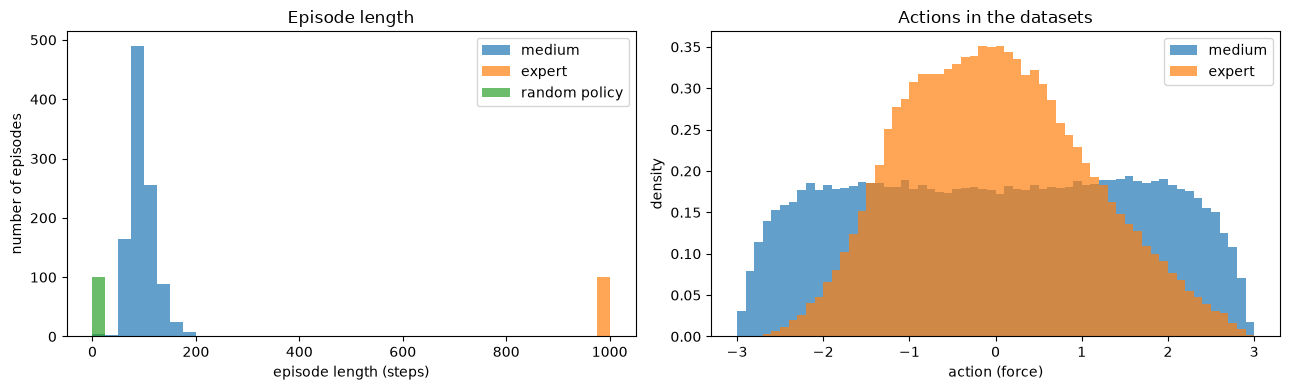

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: how long the pole stays up in each dataset (expert episodes are all at 1000)
bins = np.linspace(0, 1000, 41)
for name, (_, lengths, *_) in stats.items():
    axes[0].hist(lengths, bins=bins, alpha=0.7, label=name)
axes[0].hist(random_lengths, bins=bins, alpha=0.7, label="random policy")
axes[0].set_xlabel("episode length (steps)")
axes[0].set_ylabel("number of episodes")
axes[0].set_title("Episode length")
axes[0].legend()

# Right: which forces the agents used (density, because the datasets have different sizes)
action_bins = np.linspace(-3, 3, 61)
for name, (_, _, _, actions, _) in stats.items():
    axes[1].hist(actions, bins=action_bins, alpha=0.7, density=True, label=name)
axes[1].set_xlabel("action (force)")
axes[1].set_ylabel("density")
axes[1].set_title("Actions in the datasets")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/datasets_lengths_actions.png", dpi=120, bbox_inches="tight")
plt.show()

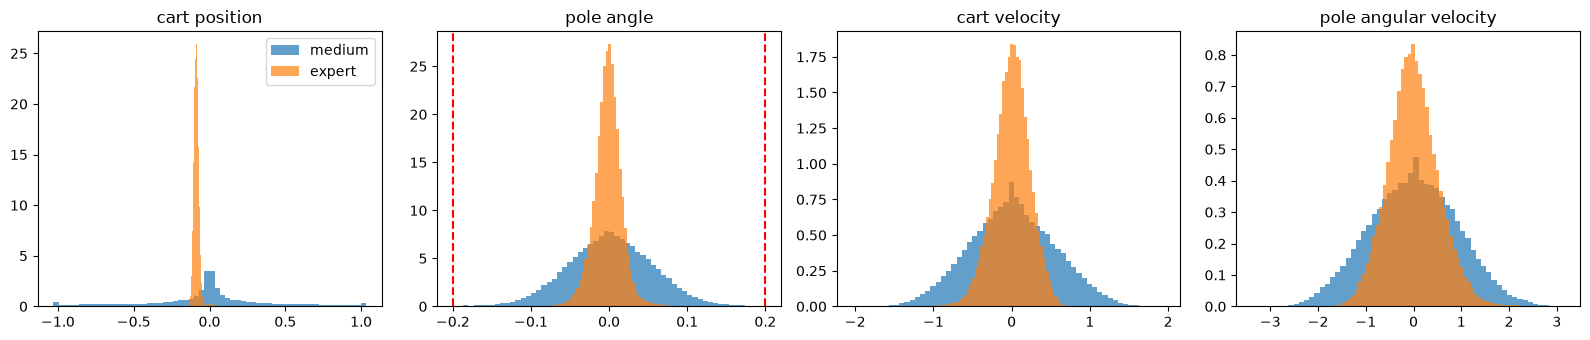

In [11]:
# Distribution of each of the 4 state variables: how far each agent lets the system move from the upright position
state_names = ["cart position", "pole angle", "cart velocity", "pole angular velocity"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for j, ax in enumerate(axes):
    for name, (*_, observations) in stats.items():
        ax.hist(observations[:, j], bins=60, alpha=0.7, density=True, label=name)
    ax.set_title(state_names[j])
# Red lines: the angle at which the episode terminates
axes[1].axvline(0.2, color="red", linestyle="--")
axes[1].axvline(-0.2, color="red", linestyle="--")
axes[0].legend()
plt.tight_layout()
plt.savefig("figures/datasets_states.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Summary (text for the video)

**Environment.** InvertedPendulum-v5 is a cart with a pole in the MuJoCo simulator. The state consists of 4 continuous
numbers (cart position, pole angle, cart velocity, pole angular velocity), the action is one continuous number in
$[-3, 3]$ (the force pushing the cart). The agent gets $+1$ for every step the pole stays upright.
The episode **terminates** when the pole tilts more than 0.2 rad (about 11.5°) and is **truncated** after 1000 steps,
so the best possible return is 1000. Both state and action are continuous, which is exactly the setting AWAC is designed for.

**Random agent.** A policy that pushes the cart randomly keeps the pole up for only about **6 steps**
(mean return **5.2** over 100 episodes, never more than 22). This is the lower bound.

**Datasets.**

| | medium-v0 | expert-v0 | random policy |
|---|---|---|---|
| episodes | 1 040 | 100 | 100 |
| transitions | 99 075 | 100 000 | 623 |
| mean return | **94.3 ± 24.7** | **1000 ± 0** | 5.2 ± 3.7 |
| best episode | 268 | 1000 | 22 |
| pole fell | 100% of episodes | never | 100% |

* The **medium** agent is much better than random, but the pole always falls, on average after about 95 steps.
  Its actions are spread over the whole range $[-3, 3]$, and in 98% of its episodes the cart drives almost to
  the end of the rail (cart position beyond $\pm 0.9$, the rail ends at $\pm 1$).
* The **expert** agent balances the pole for all 1000 steps in every episode. It uses softer actions
  (84% of them are between $-1.5$ and $1.5$) and keeps the cart and the pole close to the center.

**Why this matters for AWAC.** AWAC is trained only on the medium dataset, so it never sees a successful episode.
Each transition is weighted by $\exp(A/\lambda)$: actions that kept the pole up longer than usual get a larger weight.
The question for the experiments is how far above the average return of the data (about 94) AWAC can get,
with the random agent (about 5) as the lower bound and the expert (1000) as the upper bound.

In [12]:
# Free the simulator and rendering resources
env.close()